# 07 — ALTA10 Targeted Sensor Validation and Met Mast Geography

Continuation of **06_ALTA10_Research_Synthesis_and_Validation.ipynb**.
Focus: WTG159 (measurement anomaly), WTG180 (wake association), WTG184 (exception).

This is a self-contained script: it reads the saved 06 intermediate data and
the existing project raw/processed files. You DO NOT need to execute 06 first
in the same Python session. No files in 06 are modified.

Plan:
  1. Add a real met mast position to the original terrain + wake visualization.
  2. Plot June 8 WTG159 LiDAR / SCADA / met mast / turbine power in time.
  3. Quantify full-overlap and screened discrepancies at 159, 180 and 184.
  4. Use the SAME provisional Jensen hub-center model to restrict low-wake tests.
  5. Summarize day-block bootstrap uncertainty for targeted comparisons.
  6. Make power vs wind-speed scatter curves for the three selected turbines.

Critical caveats: met mast is at a DIFFERENT location from turbine nacelles;
elevation, heights, flow/wakes and time synchronization are unverified.
A systematic difference is NOT proof that an anemometer is faulty.

## 0. User-editable settings

Supply EITHER latitude/longitude OR UTM Zone 11N (EPSG:32611) mast coordinates.
Leave as None to generate sensor comparisons without fabricating a mast position.
The farm and DEM stay in EPSG:32611 as in notebook 06.

In [11]:
from pathlib import Path
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MET_MAST_LAT = 35.089338
MET_MAST_LON = -118.2548 
MET_MAST_EASTING_M = None   # Alternative: EPSG:32611 easting
MET_MAST_NORTHING_M = None  # Alternative: EPSG:32611 northing

FALLBACK_PROJECT_ROOT = Path(r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project")
PROJECT_ROOT_OVERRIDE = None  # Optional Path(r"...")

TARGET_TURBINES = ["WTG159", "WTG180", "WTG184"]
LIDAR_TURBINES = ["WTG159", "WTG170", "WTG171", "WTG173", "WTG180", "WTG184"]
EVENT_DAY = "2026-06-08"

# KEEP the current 06 aerodynamic assumptions, no calibration attempted.
ROTOR_DIAMETER_M = 103.0
HUB_HEIGHT_M = 85.0
RATED_POWER_KW = 2850.0
WIND_FROM_DEG = 231.72  # illustrative scenario only
FREE_STREAM_SPEED = 8.2  # m/s, illustrative scenario only
BASELINE_K = 0.05       # provisional wake expansion coefficient
CT_SPEEDS = np.array([3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12.5, 14, 16, 18, 20, 25.0])
CT_POINTS = np.array([.95, .92, .88, .83, .80, .77, .70, .58,
                      .44, .31, .25, .16, .11, .08, .06, .03])

# Other settings; match notebook 06 wherever possible.
GRID_RESOLUTION_M = 10          # notebook 06 baseline; adaptive if grid huge
GRID_PADDING_M = 1000
MAX_GRID_CELLS = 2_500_000      # limits RAM/time; changes display resolution, NOT wake physics
WAKE_THRESHOLD_PCT = 10.0
MAST_ANALYSIS_MIN_MS = 7.0
MAST_ANALYSIS_MAX_MS = 10.0
BOOTSTRAP_DRAWS = 1500
BOOTSTRAP_SEED = 42
SAVE_FIGURES = True
SAVE_TABLES = True
SHOW_PLOTS = True



## 1. Paths and reusable helpers

Mirrors notebook 06's timestamp assumption: input timestamps are interpreted
as UTC and converted to UTC-naive timestamps. This convention remains unverified.

In [12]:
def find_project_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        root = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not (root / "data" / "processed").is_dir():
            raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE is invalid: {root}")
        return root
    seeds = [Path.cwd()]
    if "__file__" in globals():
        seeds.insert(0, Path(__file__).resolve().parent)
    for seed in seeds:
        for base in (seed, *seed.parents):
            if (base / "data" / "processed").is_dir() and (base / "data" / "raw").is_dir():
                return base
    if (FALLBACK_PROJECT_ROOT / "data" / "processed").is_dir():
        return FALLBACK_PROJECT_ROOT
    raise FileNotFoundError(
        "Could not locate project data/. Put 07_ in notebooks/alex_notebooks/, "
        "or set PROJECT_ROOT_OVERRIDE at the top."
    )


def normal_id(value):
    match = re.search(r"(\d+)\s*$", str(value).strip())
    return "WTG" + match.group(1) if match else str(value).strip().upper()


def time_as_utc_naive(values):
    return pd.to_datetime(values, errors="coerce", utc=True).dt.tz_localize(None)


def fix_timestamp(frame, name):
    frame = frame.copy()
    if "timestamp" not in frame.columns and "utc" not in frame.columns:
        frame = frame.reset_index()
    time_col = next((c for c in ("timestamp", "utc") if c in frame.columns), None)
    if time_col is None:
        raise KeyError(f"{name}: no timestamp/utc column. Columns: {frame.columns.tolist()}")
    frame["timestamp"] = time_as_utc_naive(frame[time_col])
    return frame.dropna(subset=["timestamp"])


def require_unique(frame, keys, name):
    duplicates = frame.duplicated(keys, keep=False)
    if duplicates.any():
        preview = frame.loc[duplicates, keys].head(5).to_string(index=False)
        raise ValueError(f"{name} has {duplicates.sum():,} duplicate-key rows.\n{preview}")


def save_table(table, name):
    if SAVE_TABLES:
        table.to_csv(RESULT_DIR / f"{name}.csv", index=False)


def finish_plot(fig, name):
    if SAVE_FIGURES:
        fig.savefig(RESULT_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


def find_input(filename):
    hits = sorted(DATA_DIR.rglob(filename))
    if not hits:
        raise FileNotFoundError(f"Cannot locate {filename} beneath {DATA_DIR}")
    return hits[0]


def bool_col(s):
    if pd.api.types.is_bool_dtype(s):
        return s.fillna(False)
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "yes", "t"])


def candidate_ct(u):
    """IDENTICAL interpolation and cutoff to notebook 06. NOT an OEM Ct curve."""
    a = np.asarray(u, dtype=float)
    result = np.interp(a, CT_SPEEDS, CT_POINTS)
    result = np.where((a < 4.0) | (a >= 25.0), 0.0, result)
    return float(result) if result.ndim == 0 else result




## 2. Load met mast, turbine SCADA, and matched 06 LiDAR output

Prefer the reviewed 06 CSV files. If absent, rebuild 10-minute LiDAR data
from the original per-day 1-second files, using the SAME 06 eligibility rules.

In [13]:
def load_scada(root):
    path = root / "data" / "processed" / "scada_data.parquet"
    df = pd.read_parquet(path)
    df = fix_timestamp(df, "SCADA")
    df["turbine"] = df["turbine"].map(normal_id)
    df = df[df["turbine"].isin(TARGET_TURBINES)].copy()
    needed = ["wind_speed", "real_power_ac", "wind_direction", "air_density"]
    for col in needed:
        if col not in df.columns:
            df[col] = np.nan
        df[col] = pd.to_numeric(df[col], errors="coerce")
    require_unique(df, ["timestamp", "turbine"], "SCADA")
    return df


def load_mast(root):
    path = root / "data" / "processed" / "metmasts_data.parquet"
    df = pd.read_parquet(path)
    df = fix_timestamp(df, "met mast")
    required = ["mm_wind_speed_3", "mm_wind_direction_3"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Mast data missing {missing}. Columns: {list(df.columns)}")
    optional = ["mm_wind_speed_hh", "mm_wind_direction_hh", "mm_wind_speed_2", "mm_wind_direction_2"]
    for col in required + optional:
        if col not in df.columns:
            df[col] = np.nan
        df[col] = pd.to_numeric(df[col], errors="coerce")
    require_unique(df, ["timestamp"], "met mast")
    return df[["timestamp"] + required + optional].copy()


def rebuild_lidar_day(path, turbine):
    """Copy 06's 1-second -> 10-minute wind speed and anomaly rules."""
    cols = {"timestamp", "lidar_wsp", "sensor1_wsp"}
    d = pd.read_csv(path, usecols=lambda c: c in cols)
    if not cols.issubset(d.columns):
        raise ValueError(f"Raw LiDAR source missing required fields: {path}")
    d["timestamp"] = time_as_utc_naive(d["timestamp"])
    d = d.dropna(subset=["timestamp"]).sort_values("timestamp").drop_duplicates("timestamp")
    lidar = pd.to_numeric(d["lidar_wsp"], errors="coerce")
    sensor = pd.to_numeric(d["sensor1_wsp"], errors="coerce")
    paired = lidar.between(0, 50) & sensor.between(0, 50)
    high = paired & sensor.gt(20)
    d["valid_speed"] = lidar.where(lidar.between(0, 35))
    d["high"] = high.astype("int8")
    d["flag"] = (high & lidar.lt(8)).astype("int8")
    agg = d.set_index("timestamp").resample("10min").agg(
        valid_seconds=("valid_speed", "count"),
        lidar_speed=("valid_speed", "mean"),
        high_sensor_seconds=("high", "sum"),
        flagged_seconds=("flag", "sum")
    )
    valid = agg.valid_seconds.ge(540) & agg.lidar_speed.ge(3)
    fraction = agg.flagged_seconds / agg.high_sensor_seconds.replace(0, np.nan)
    agg["flagged_interval"] = agg.high_sensor_seconds.ge(120) & fraction.ge(.5)
    agg.loc[~valid, "lidar_speed"] = np.nan
    agg["turbine"] = turbine
    return agg.reset_index()[["timestamp", "turbine", "lidar_speed", "flagged_interval"]]


def load_lidar_pairs(root, scada):
    previous = root / "data" / "processed" / "06_research_synthesis"
    matched_path = previous / "05_scada_lidar_matched.csv"
    lidar10_path = previous / "02_lidar_all_10min.csv"

    if matched_path.is_file():
        print(f"Using matched 06 output: {matched_path}")
        df = pd.read_csv(matched_path, low_memory=False)
        df = fix_timestamp(df, "06 matched LiDAR/SCADA")
        df["turbine"] = df["turbine"].map(normal_id)
        df = df[df.turbine.isin(TARGET_TURBINES)].copy()
        # 'power_kw' in 06 came from real_power_ac and is already expressed in kW.
        for col in ["lidar_speed", "scada_speed", "power_kw", "air_density"]:
            if col not in df.columns:
                df[col] = np.nan
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df["flagged_interval"] = bool_col(df["flagged_interval"]) if "flagged_interval" in df else False
        require_unique(df, ["timestamp", "turbine"], "06 matched CSV")
        return df

    if lidar10_path.is_file():
        print(f"Using 06 LiDAR 10-minute output: {lidar10_path}")
        lidar = pd.read_csv(lidar10_path, low_memory=False)
        lidar = fix_timestamp(lidar, "06 LiDAR intervals")
        lidar["turbine"] = lidar["turbine"].map(normal_id)
        lidar = lidar[lidar.turbine.isin(TARGET_TURBINES)].copy()
        if "valid_interval" in lidar:
            lidar = lidar[bool_col(lidar.valid_interval)].copy()
        lidar = lidar.rename(columns={"mean_speed": "lidar_speed"})
        lidar["flagged_interval"] = bool_col(lidar["flagged_interval"])
        lidar = lidar[["timestamp", "turbine", "lidar_speed", "flagged_interval"]]
    else:
        print("06 output not found: rebuilding target-turbine 10-minute LiDAR series.")
        parts = []
        raw_root = root / "data" / "raw" / "lidar_data"
        for turbine in TARGET_TURBINES:
            paths = sorted((raw_root / f"WTG_T{turbine[3:]}").glob("*.csv"))
            if not paths:
                raise FileNotFoundError(f"No raw LiDAR daily CSVs for {turbine}: {raw_root}")
            for p in paths:
                parts.append(rebuild_lidar_day(p, turbine))
            print(f"  {turbine}: {len(paths)} daily files")
        lidar = pd.concat(parts, ignore_index=True).dropna(subset=["lidar_speed"])
    require_unique(lidar, ["timestamp", "turbine"], "LiDAR 10-minute data")
    power = scada[["timestamp", "turbine", "wind_speed", "real_power_ac", "air_density"]].rename(
        columns={"wind_speed": "scada_speed", "real_power_ac": "power_kw"}
    )
    df = lidar.merge(power, on=["timestamp", "turbine"], how="inner", validate="one_to_one")
    return df


def match_three_sources(pairs, mast):
    useful = ["timestamp", "mm_wind_speed_3", "mm_wind_direction_3", "mm_wind_speed_hh",
              "mm_wind_direction_hh", "mm_wind_speed_2", "mm_wind_direction_2"]
    merged = pairs.merge(mast[useful], on="timestamp", how="inner", validate="many_to_one")
    for col in ["lidar_speed", "scada_speed", "power_kw", "air_density"]:
        merged[col] = pd.to_numeric(merged[col], errors="coerce")
    for c in ["lidar_speed", "scada_speed", "mm_wind_speed_3", "mm_wind_speed_hh"]:
        merged.loc[~merged[c].between(0, 35), c] = np.nan
    merged["flagged_interval"] = bool_col(merged.flagged_interval)
    merged["scada_minus_lidar"] = merged.scada_speed - merged.lidar_speed
    merged["scada_minus_mast3"] = merged.scada_speed - merged.mm_wind_speed_3
    merged["lidar_minus_mast3"] = merged.lidar_speed - merged.mm_wind_speed_3
    merged["scada_over_mast3"] = merged.scada_speed / merged.mm_wind_speed_3.where(
        merged.mm_wind_speed_3 > 0
    )
    merged["lidar_over_mast3"] = merged.lidar_speed / merged.mm_wind_speed_3.where(
        merged.mm_wind_speed_3 > 0
    )
    return merged




## 3. Coordinate prep and EXACT 06 wake equations

The candidate thrust curve consists of assumed points in 06; at 8.2 m/s
linear interpolation between Ct(8)=0.77 and Ct(9)=0.70 gives **Ct=0.756**.
This curve was not fitted or uniquely recovered from the GE power curve.
The Gaussian-style approximation is NOT a full published Gaussian model.

In [14]:
def mast_xy():
    ll = MET_MAST_LAT is not None or MET_MAST_LON is not None
    utm = MET_MAST_EASTING_M is not None or MET_MAST_NORTHING_M is not None
    if ll and utm:
        raise ValueError("Provide only lat/lon OR UTM easting/northing for met mast.")
    if ll:
        if MET_MAST_LAT is None or MET_MAST_LON is None:
            raise ValueError("Supply BOTH MET_MAST_LAT and MET_MAST_LON.")
        lat, lon = float(MET_MAST_LAT), float(MET_MAST_LON)
        if not (-90 <= lat <= 90 and -180 <= lon <= 180):
            raise ValueError("Invalid met mast latitude or longitude.")
        from pyproj import Transformer
        return Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True).transform(lon, lat)
    if utm:
        if MET_MAST_EASTING_M is None or MET_MAST_NORTHING_M is None:
            raise ValueError("Supply BOTH UTM easting and northing.")
        return float(MET_MAST_EASTING_M), float(MET_MAST_NORTHING_M)
    return None


def load_farm_and_dem(root):
    from pyproj import Transformer
    import rasterio
    coord_file = find_input("turbine_coordinate_ALTA10.csv")
    coordinates = pd.read_csv(coord_file)
    required = {"Turbine_ID", "Latitude", "Longitude"}
    if not required.issubset(coordinates.columns):
        raise KeyError(f"Missing coordinate columns from {coord_file}")
    coordinates["turbine"] = coordinates.Turbine_ID.map(normal_id)
    for c in ["Latitude", "Longitude"]:
        coordinates[c] = pd.to_numeric(coordinates[c], errors="coerce")
    coordinates = coordinates[["turbine", "Latitude", "Longitude"]].dropna().drop_duplicates("turbine")
    transformer = Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True)
    x, y = transformer.transform(coordinates.Longitude.to_numpy(), coordinates.Latitude.to_numpy())
    farm = coordinates.assign(x=x, y=y)
    dem_path = find_input("elevation.tif")
    with rasterio.open(dem_path) as src:
        from rasterio.warp import transform as transform_xy
        e, n = transform_xy("EPSG:32611", src.crs, farm.x.tolist(), farm.y.tolist())
        samples = list(src.sample(zip(e, n), masked=True))
        farm["elevation_m"] = [
            float(v[0]) if (not np.ma.is_masked(v[0]) and np.isfinite(float(v[0]))) else np.nan
            for v in samples
        ]
    if farm.elevation_m.isna().any():
        raise ValueError("DEM does not contain elevations for all turbines; check raster/CRS.")
    return farm, dem_path


def wake_map_grid(model, terrain, X, Y, farm):
    """Same 06 terrain-wake calculation; fixed 06 assumptions."""
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("Unknown wake model")
    theta = np.deg2rad(WIND_FROM_DEG)
    dx, dy = -np.sin(theta), -np.cos(theta)
    ct = candidate_ct(FREE_STREAM_SPEED)
    combined_sq = np.zeros_like(terrain, dtype=float)
    for src in farm.itertuples():
        downstream = (X - src.x) * dx + (Y - src.y) * dy
        crosswind = -(X - src.x) * dy + (Y - src.y) * dx
        positive = np.maximum(downstream, 0)
        vertical = terrain - src.elevation_m
        center = (1 - np.sqrt(1 - ct)) / (1 + 2 * BASELINE_K * positive / ROTOR_DIAMETER_M)**2
        radius = ROTOR_DIAMETER_M / 2 + BASELINE_K * positive
        if model == "jensen":
            delta = np.where((downstream > 0) &
                             (np.hypot(crosswind, vertical) <= radius), center, 0)
        else:
            gauss = np.exp(-.5 * ((crosswind / radius)**2 + (vertical / radius)**2))
            delta = np.where(downstream > 0, center * gauss, 0)
        delta[~np.isfinite(terrain)] = 0
        combined_sq += delta**2
    return np.minimum(1., np.sqrt(combined_sq))


def hub_predictions_at_direction(farm, direction_deg, model="jensen"):
    """Copy of notebook 06 hub_predictions evaluated at a supplied wind-from angle."""
    theta = np.deg2rad(direction_deg)
    dx, dy = -np.sin(theta), -np.cos(theta)
    ct = candidate_ct(FREE_STREAM_SPEED)
    rows = []
    for target in farm.itertuples():
        if target.turbine not in TARGET_TURBINES:
            continue
        sq = 0.0
        for source in farm.itertuples():
            if target.turbine == source.turbine:
                continue
            ex, ey = target.x - source.x, target.y - source.y
            along = ex * dx + ey * dy
            if along <= 0 or ct <= 0:
                continue
            across = -ex * dy + ey * dx
            vert = target.elevation_m - source.elevation_m
            radius = ROTOR_DIAMETER_M / 2 + BASELINE_K * along
            center = (1 - np.sqrt(1 - ct)) / (1 + 2 * BASELINE_K * along / ROTOR_DIAMETER_M)**2
            if model == "jensen":
                delta = center if np.hypot(across, vert) <= radius else 0.0
            else:
                delta = center * np.exp(-.5 * ((across / radius)**2 + (vert / radius)**2))
            sq += delta**2
        rows.append({"turbine": target.turbine, "wind_from_deg": int(direction_deg),
                     "predicted_deficit_pct": 100 * min(np.sqrt(sq), 1.)})
    return rows


def label_wake_exposure(merged, farm):
    lookup = pd.DataFrame([
        row for angle in np.arange(0, 360, 5)
        for row in hub_predictions_at_direction(farm, int(angle), model="jensen")
    ])
    save_table(lookup, "07_target_directional_jensen_lookup")
    valid_dir = merged.mm_wind_direction_3.between(0, 360, inclusive="left")
    merged = merged.copy()
    merged["wind_from_deg"] = np.nan
    merged.loc[valid_dir, "wind_from_deg"] = (
        (np.floor((merged.loc[valid_dir, "mm_wind_direction_3"] + 2.5) / 5) * 5) % 360
    )
    merged = merged.merge(lookup, on=["turbine", "wind_from_deg"], how="left", validate="many_to_one")
    merged["wake_class"] = np.select(
        [merged.predicted_deficit_pct.ge(WAKE_THRESHOLD_PCT),
         merged.predicted_deficit_pct.lt(WAKE_THRESHOLD_PCT)],
        ["Modeled wake", "Low wake"], default="Unknown"
    )
    return merged




## 4. Terrain + wake maps with the met mast positioned as an OBSERVER

Reproject the original DEM to a shared UTM grid. The mast is a marker and
does NOT emit a turbine wake. Expands the grid if the mast is outside the farm.

In [15]:
def terrain_grid(farm, dem_path, mast_position):
    import rasterio
    from rasterio.warp import reproject, Resampling
    from rasterio.transform import from_origin
    xs, ys = farm.x.to_numpy(), farm.y.to_numpy()
    if mast_position is not None:
        xs = np.append(xs, mast_position[0])
        ys = np.append(ys, mast_position[1])
    x0, x1 = float(xs.min() - GRID_PADDING_M), float(xs.max() + GRID_PADDING_M)
    y0, y1 = float(ys.min() - GRID_PADDING_M), float(ys.max() + GRID_PADDING_M)
    resolution = float(GRID_RESOLUTION_M)
    while np.ceil((x1-x0)/resolution) * np.ceil((y1-y0)/resolution) > MAX_GRID_CELLS:
        resolution *= 1.25
    nx = int(np.ceil((x1-x0)/resolution))
    ny = int(np.ceil((y1-y0)/resolution))
    x1, y1 = x0 + nx*resolution, y0 + ny*resolution
    arr = np.full((ny, nx), np.nan, dtype=np.float32)
    with rasterio.open(dem_path) as dem:
        reproject(source=rasterio.band(dem, 1), destination=arr,
                  src_transform=dem.transform, src_crs=dem.crs, src_nodata=dem.nodata,
                  dst_transform=from_origin(x0, y1, resolution, resolution),
                  dst_crs="EPSG:32611", dst_nodata=np.nan,
                  resampling=Resampling.bilinear)
    if not np.isfinite(arr).any():
        raise ValueError("DEM does not cover the selected map region.")
    xvec = x0 + (np.arange(nx) + .5)*resolution
    yvec = y1 - (np.arange(ny) + .5)*resolution
    X, Y = np.meshgrid(xvec, yvec)
    print(f"Map raster: {nx} x {ny}; effective resolution {resolution:.1f} m")
    return arr, X, Y, (x0, x1, y0, y1)


def plot_mast_terrain_wakes(farm, dem_path, position):
    terrain, X, Y, extent = terrain_grid(farm, dem_path, position)
    colors = {"WTG159": "#d62728", "WTG180": "#ff7f0e", "WTG184": "#9467bd"}
    fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True,
                             constrained_layout=True)
    back_im = overlay_im = None
    for ax, model, title in zip(axes, ["jensen", "gaussian_style"], ["Jensen", "Gaussian-style"]):
        loss = wake_map_grid(model, terrain, X, Y, farm)
        back_im = ax.imshow(terrain, extent=extent, origin="upper", cmap="terrain",
                            vmin=np.nanpercentile(terrain, 2), vmax=np.nanpercentile(terrain, 98))
        overlay = np.ma.masked_where((loss < .01) | ~np.isfinite(terrain), 100*loss)
        overlay_im = ax.imshow(overlay, extent=extent, origin="upper", cmap="Blues",
                               alpha=.47, vmin=0, vmax=50)
        ax.scatter(farm.x, farm.y, s=18, c="lightgray", edgecolor="black", linewidth=.5,
                   zorder=5, label="Other turbines")
        for target in TARGET_TURBINES:
            row = farm.loc[farm.turbine.eq(target)]
            if row.empty:
                warnings.warn(f"Missing turbine coordinate: {target}")
                continue
            tx, ty = float(row.x.iloc[0]), float(row.y.iloc[0])
            ax.scatter(tx, ty, s=125, c=colors[target], edgecolors="white", linewidth=1.2,
                       zorder=7, label=target)
            ax.annotate(target, (tx, ty), xytext=(7, 7), textcoords="offset points",
                        fontsize=9, fontweight="bold", zorder=8)
        if position is not None:
            ax.scatter(*position, marker="*", s=450, c="yellow", edgecolor="black",
                       linewidth=1.4, zorder=10, label="Met mast")
            ax.annotate("MET MAST", position, xytext=(10, 10), textcoords="offset points",
                        fontsize=10, fontweight="bold", zorder=11)
        ax.set_title(f"{title} | wind from {WIND_FROM_DEG:.2f}°, {FREE_STREAM_SPEED} m/s")
        ax.set_xlabel("UTM Zone 11N easting (m)")
        ax.set_ylabel("UTM Zone 11N northing (m)")
        ax.set_aspect("equal")
        ax.legend(loc="best", fontsize=8)
    fig.colorbar(back_im, ax=axes, label="Ground elevation (m)", fraction=.022, pad=.01)
    fig.colorbar(overlay_im, ax=axes, label="Provisional speed deficit (%)", fraction=.022, pad=.07)
    fig.suptitle("ALTA10 | Existing wake scenarios, terrain, targets and met mast", fontsize=15)
    finish_plot(fig, "07_terrain_wakes_met_mast")

    if position is not None:
        from rasterio.warp import transform as raster_transform
        import rasterio
        with rasterio.open(dem_path) as src:
            mast_e, mast_n = raster_transform("EPSG:32611", src.crs,
                                               [position[0]], [position[1]])
            mast_sample = list(src.sample([(mast_e[0], mast_n[0])], masked=True))[0][0]
        mast_elevation = float(mast_sample) if not np.ma.is_masked(mast_sample) else np.nan
        rows = []
        for name in TARGET_TURBINES:
            t = farm.loc[farm.turbine.eq(name)]
            if t.empty:
                continue
            tx, ty = float(t.x.iloc[0]), float(t.y.iloc[0])
            dx, dy = tx - position[0], ty - position[1]
            rows.append({
                "turbine": name,
                "horizontal_distance_km": np.hypot(dx, dy)/1000,
                "bearing_mast_to_turbine_deg": (np.degrees(np.arctan2(dx, dy)) % 360),
                "mast_terrain_elevation_m": mast_elevation,
                "turbine_terrain_elevation_m": float(t.elevation_m.iloc[0]),
                "terrain_elevation_difference_m": float(t.elevation_m.iloc[0])-mast_elevation
            })
        distances = pd.DataFrame(rows)
        print("\nMet mast geometry relative to investigation turbines:")
        print(distances.round(2).to_string(index=False))
        save_table(distances, "07_mast_target_geometry")




## 5. June 8, 2026 WTG159 — time-aligned wind and electrical power

06's 1-Hz Sensor 1 is plotted if available, but it is NOT assumed calibrated.
We do not fill gaps or shift timestamps. The sponsor must confirm whether
each data source labels the start/end of the same 10-minute average window.

In [16]:
def load_sensor1_event(root):
    path = root / "data" / "raw" / "lidar_data" / "WTG_T159" / f"{EVENT_DAY}.csv"
    if not path.is_file():
        print(f"No raw Sensor 1 event file at {path}; skipping Sensor 1 overlay")
        return None
    d = pd.read_csv(path, usecols=lambda c: c in {"timestamp", "sensor1_wsp", "lidar_wsp"})
    if not {"timestamp", "sensor1_wsp", "lidar_wsp"}.issubset(d.columns):
        return None
    d = fix_timestamp(d, "WTG159 raw event")
    for c in ["sensor1_wsp", "lidar_wsp"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.drop_duplicates("timestamp").set_index("timestamp")
    d["sensor1_wsp"] = d.sensor1_wsp.where(d.sensor1_wsp.between(0, 50))
    d["lidar_wsp"] = d.lidar_wsp.where(d.lidar_wsp.between(0, 35))
    return d.resample("10min").agg({"sensor1_wsp": "mean", "lidar_wsp": "mean"})


def plot_wtg159_event(merged, root):
    g = merged.loc[merged.turbine.eq("WTG159")].copy()
    start = pd.Timestamp(EVENT_DAY)
    end = start + pd.Timedelta(days=1)
    event = g.loc[g.timestamp.ge(start) & g.timestamp.lt(end)].copy()
    if event.empty:
        warnings.warn(f"No WTG159 matched observations on {EVENT_DAY}")
        return
    sensor = load_sensor1_event(root)
    if sensor is not None:
        event = event.merge(sensor[["sensor1_wsp"]], left_on="timestamp", right_index=True,
                            how="left", validate="one_to_one")

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                             gridspec_kw={"height_ratios": [2.3, 1]})
    sources = [
        ("lidar_speed", "LiDAR reconstructed", "tab:blue"),
        ("scada_speed", "SCADA wind speed", "tab:orange"),
        ("mm_wind_speed_3", "Met mast channel 3", "tab:green"),
        ("mm_wind_speed_hh", "Met mast hub-height", "tab:purple"),
    ]
    if "sensor1_wsp" in event:
        sources.append(("sensor1_wsp", "LiDAR-file Sensor 1", "tab:red"))
    for col, label, color in sources:
        axes[0].plot(event.timestamp, event[col], marker=".", lw=1.5, ms=3,
                     label=label, color=color)
    axes[0].set_ylabel("Wind speed (m/s)")
    axes[0].set_title(f"WTG159 | {EVENT_DAY}: LiDAR, SCADA, remote mast and Sensor 1")
    axes[0].legend(loc="best", ncol=2, fontsize=9)
    axes[0].grid(alpha=.25)

    axes[1].plot(event.timestamp, event.power_kw, color="black", lw=1.7,
                 marker=".", ms=3, label="WTG159 actual power")
    axes[1].set_ylabel("Electrical power (kW)")
    axes[1].set_xlabel("Timestamp (UTC, 10-minute labels unverified)")
    axes[1].grid(alpha=.25)
    axes[1].legend()
    fig.autofmt_xdate()
    fig.tight_layout()
    finish_plot(fig, "07_wtg159_june08_winds_and_power")
    save_table(event, "07_wtg159_june08_matched")
    print(f"WTG159 June 8 matched 10-minute intervals: {len(event)}")




## 6. Three target turbines — quality screens, biases, and day-block uncertainty

'Low wake' here uses the unchanged 06 Jensen hub-center geometry, 10% deficit
threshold, mast Channel 3 direction, and 7–10 m/s mast inflow. Not proof of
a wake, not an actual speed loss, and not a verified mast turbine equivalence.
We tabulate multiple screens rather than cherry-pick a favorite result.

In [17]:
def summarize_subset(g, scenario):
    if g.empty:
        return None
    return {
        "turbine": g.turbine.iloc[0], "scenario": scenario, "n": len(g),
        "mean_scada_minus_lidar_ms": g.scada_minus_lidar.mean(),
        "median_scada_minus_lidar_ms": g.scada_minus_lidar.median(),
        "mean_scada_minus_mast3_ms": g.scada_minus_mast3.mean(),
        "mean_lidar_minus_mast3_ms": g.lidar_minus_mast3.mean(),
        "mean_scada_over_mast3": g.scada_over_mast3.mean(),
        "mean_lidar_over_mast3": g.lidar_over_mast3.mean(),
        "n_distinct_days": g.timestamp.dt.normalize().nunique()
    }


def screen_target_data(merged):
    data = merged.copy()
    data["usable"] = (
        data.lidar_speed.between(3, 25) &
        data.scada_speed.between(3, 25) &
        data.mm_wind_speed_3.between(3, 25)
    )
    data["unflagged"] = data.usable & ~data.flagged_interval
    data["normal_power_proxy"] = data.unflagged & data.power_kw.between(100, RATED_POWER_KW)
    data["ambient_7_10"] = (
        data.normal_power_proxy &
        data.mm_wind_speed_3.between(MAST_ANALYSIS_MIN_MS, MAST_ANALYSIS_MAX_MS)
    )
    data["low_wake_screen"] = data.ambient_7_10 & data.wake_class.eq("Low wake")
    data["wake_screen"] = data.ambient_7_10 & data.wake_class.eq("Modeled wake")
    rows = []
    subsets = [
        ("All valid triple matches", "usable"),
        ("Exclude 06 anomaly flags", "unflagged"),
        ("Generation proxy 100–2850 kW", "normal_power_proxy"),
        ("Mast channel 3 at 7–10 m/s", "ambient_7_10"),
        ("Low modeled wake <10%", "low_wake_screen"),
        ("Modeled wake >=10%", "wake_screen")
    ]
    for turbine, group in data.groupby("turbine"):
        for name, flag in subsets:
            row = summarize_subset(group.loc[group[flag]], name)
            if row:
                rows.append(row)
    summary = pd.DataFrame(rows)
    print("\nTarget-turbine signed differences (remote met mast is NOT local ground truth):")
    print(summary.round(3).to_string(index=False))
    save_table(summary, "07_target_comparison_by_screen")
    save_table(data, "07_target_all_three_sources_matched")
    return data


def bootstrap_daily_mean(data, scenario_col="low_wake_screen"):
    """Whole-day bootstrap of the mean SCADA minus LiDAR difference.

    Statistically quantifies persistence; it does not remove wind-sector or
    geography confounding. Entire-day resampling partially addresses serial
    correlation within days, but not across consecutive days.
    """
    rows = []
    for i, turbine in enumerate(TARGET_TURBINES):
        g = data[(data.turbine == turbine) & data[scenario_col]].copy()
        g = g.dropna(subset=["scada_minus_lidar"])
        if len(g) < 20:
            rows.append({"turbine": turbine, "n": len(g), "days": 0,
                         "mean_diff_ms": np.nan, "ci_low": np.nan, "ci_high": np.nan})
            continue
        g["date"] = g.timestamp.dt.normalize()
        daily = g.groupby("date").agg(n=("scada_minus_lidar", "size"),
                                       total=("scada_minus_lidar", "sum"))
        n_days = len(daily)
        nums = daily.n.to_numpy(dtype=float)
        sums = daily.total.to_numpy(dtype=float)
        rng = np.random.default_rng(BOOTSTRAP_SEED + i)
        ix = rng.integers(0, n_days, size=(BOOTSTRAP_DRAWS, n_days))
        boot = sums[ix].sum(axis=1) / nums[ix].sum(axis=1)
        rows.append({"turbine": turbine, "n": len(g), "days": n_days,
                     "mean_diff_ms": g.scada_minus_lidar.mean(),
                     "ci_low": np.percentile(boot, 2.5),
                     "ci_high": np.percentile(boot, 97.5)})
    outcome = pd.DataFrame(rows)
    print(f"\nDay-block bootstrap on {scenario_col}:")
    print(outcome.round(3).to_string(index=False))
    save_table(outcome, f"07_bootstrap_{scenario_col}")
    return outcome


def plot_target_mast_comparisons(data):
    g = data.loc[data.unflagged & data.mm_wind_speed_3.between(3, 25)].copy()
    if g.empty:
        print("No usable triple-source rows for scatter figures.")
        return
    fig, axs = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
    for ax, turbine in zip(axs, TARGET_TURBINES):
        x = g[g.turbine.eq(turbine)]
        ax.scatter(x.mm_wind_speed_3, x.lidar_speed, s=7, alpha=.17,
                   label="LiDAR vs mast", color="tab:blue")
        ax.scatter(x.mm_wind_speed_3, x.scada_speed, s=7, alpha=.17,
                   label="SCADA vs mast", color="tab:orange")
        ax.plot([0, 25], [0, 25], "k--", lw=1, label="1:1 guide")
        ax.set_title(f"{turbine} | n={len(x):,}")
        ax.set(xlabel="Met mast channel 3 (m/s)", ylabel="Turbine wind report (m/s)")
        ax.grid(alpha=.18)
        ax.legend(fontsize=8)
    fig.suptitle("ALTA10 | Remote mast vs turbine reports — not a calibration check")
    fig.tight_layout()
    finish_plot(fig, "07_target_scada_lidar_vs_mast_scatter")




## 7. Diagnostic manufacturer-power comparisons for the three targets

Same actual power is displayed against three different reported speeds, not
three independently measured powers. Mast speed is remote, so displacement
of its point cloud should NOT be read as mast calibration error.

In [18]:
def load_reference_curve(root):
    path = find_input("GE_2_85MW_103mRD_PC.csv")
    curve = pd.read_csv(path)
    curve.columns = curve.columns.str.strip()
    for c in ["WINDSPEED", "POWER_KW", "AIR_DENSITY"]:
        curve[c] = pd.to_numeric(curve[c], errors="coerce")
    curve = curve[np.isclose(curve.AIR_DENSITY, 1.02, atol=.001) &
                  curve.TI_CLASS.astype(str).str.strip().str.lower().eq("normal")]
    curve = (curve.dropna(subset=["WINDSPEED", "POWER_KW"])
             .groupby("WINDSPEED", as_index=False)["POWER_KW"].mean()
             .sort_values("WINDSPEED"))
    if len(curve) < 2:
        raise ValueError("Reference curve has fewer than two points at density 1.02, normal TI")
    return curve


def plot_power_curves(data, ref):
    # Only a first-pass operation proxy: no fault / curtailment / density correction.
    selected = data.loc[data.normal_power_proxy].copy()
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)
    for ax, turbine in zip(axes, TARGET_TURBINES):
        sub = selected.loc[selected.turbine.eq(turbine)]
        ax.plot(ref.WINDSPEED, ref.POWER_KW, color="black", lw=2,
                label="GE reference (1.02 kg/m³, normal TI)")
        for col, label, color in [
            ("lidar_speed", "Power @ LiDAR speed", "tab:blue"),
            ("scada_speed", "Power @ SCADA speed", "tab:orange"),
            ("mm_wind_speed_3", "Power @ remote mast ch. 3", "tab:green")
        ]:
            ax.scatter(sub[col], sub.power_kw, s=9, alpha=.18, c=color, label=label)
        ax.set_xlim(0, 20); ax.set_ylim(0, 3000)
        ax.set(title=f"{turbine} | n={len(sub):,}", xlabel="Reported wind speed (m/s)",
               ylabel="Actual turbine electrical power (kW)")
        ax.grid(alpha=.2)
        ax.legend(fontsize=7.5)
    fig.suptitle("ALTA10 | Same turbine power, three reported wind speeds — diagnostic only")
    fig.tight_layout()
    finish_plot(fig, "07_target_three_source_power_curves")




## 8. Execute this research phase

Prints diagnostics even if you have not entered mast location yet.
Geography requires coordinates, but sensor matching only requires mast data.
Outputs are saved to `data/processed/07_targeted_sensor_validation/`.

Project root: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project
Output folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\07_targeted_sensor_validation
Candidate Ct at 8.2 m/s = 0.756 (provisional 06 curve)
Using matched 06 output: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\06_research_synthesis\05_scada_lidar_matched.csv
LiDAR-SCADA rows: 44881 | Mast rows: 39306
Triple-source time-matched rows: 44881
  WTG159: 15,018 triple-source samples
  WTG180: 15,188 triple-source samples
  WTG184: 14,675 triple-source samples
Turbine locations: 47 | DEM: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\terrain\elevation.tif
Map raster: 606 x 521; effective resolution 10.0 m


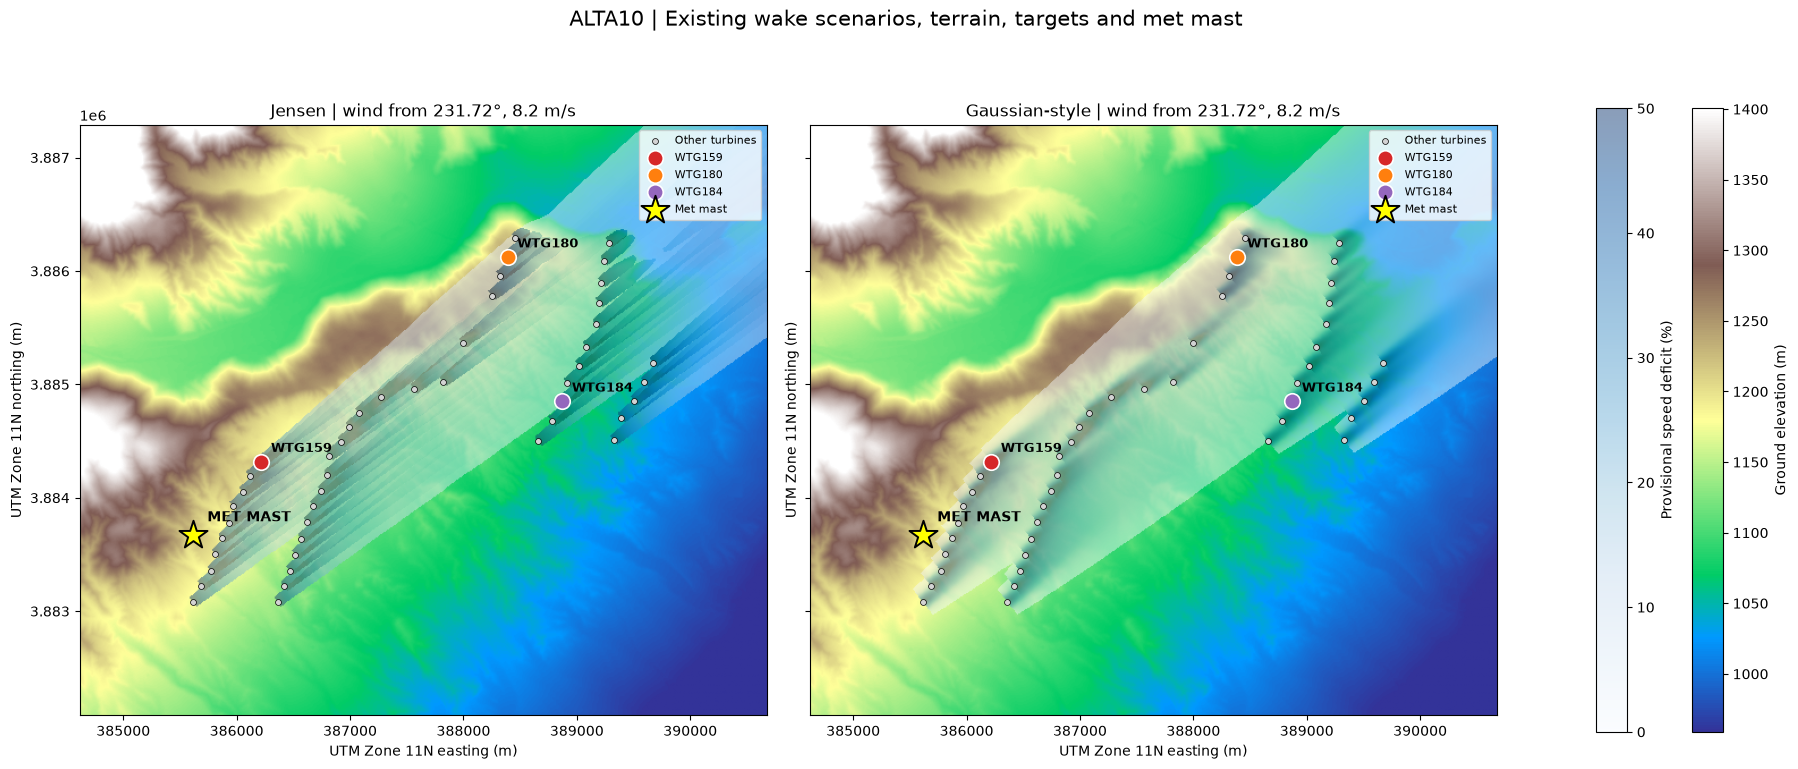


Met mast geometry relative to investigation turbines:
turbine  horizontal_distance_km  bearing_mast_to_turbine_deg  mast_terrain_elevation_m  turbine_terrain_elevation_m  terrain_elevation_difference_m
 WTG159                    0.88                        42.65                    1225.2                      1207.18                          -18.02
 WTG180                    3.70                        48.48                    1225.2                      1225.55                            0.35
 WTG184                    3.46                        70.05                    1225.2                      1079.75                         -145.46


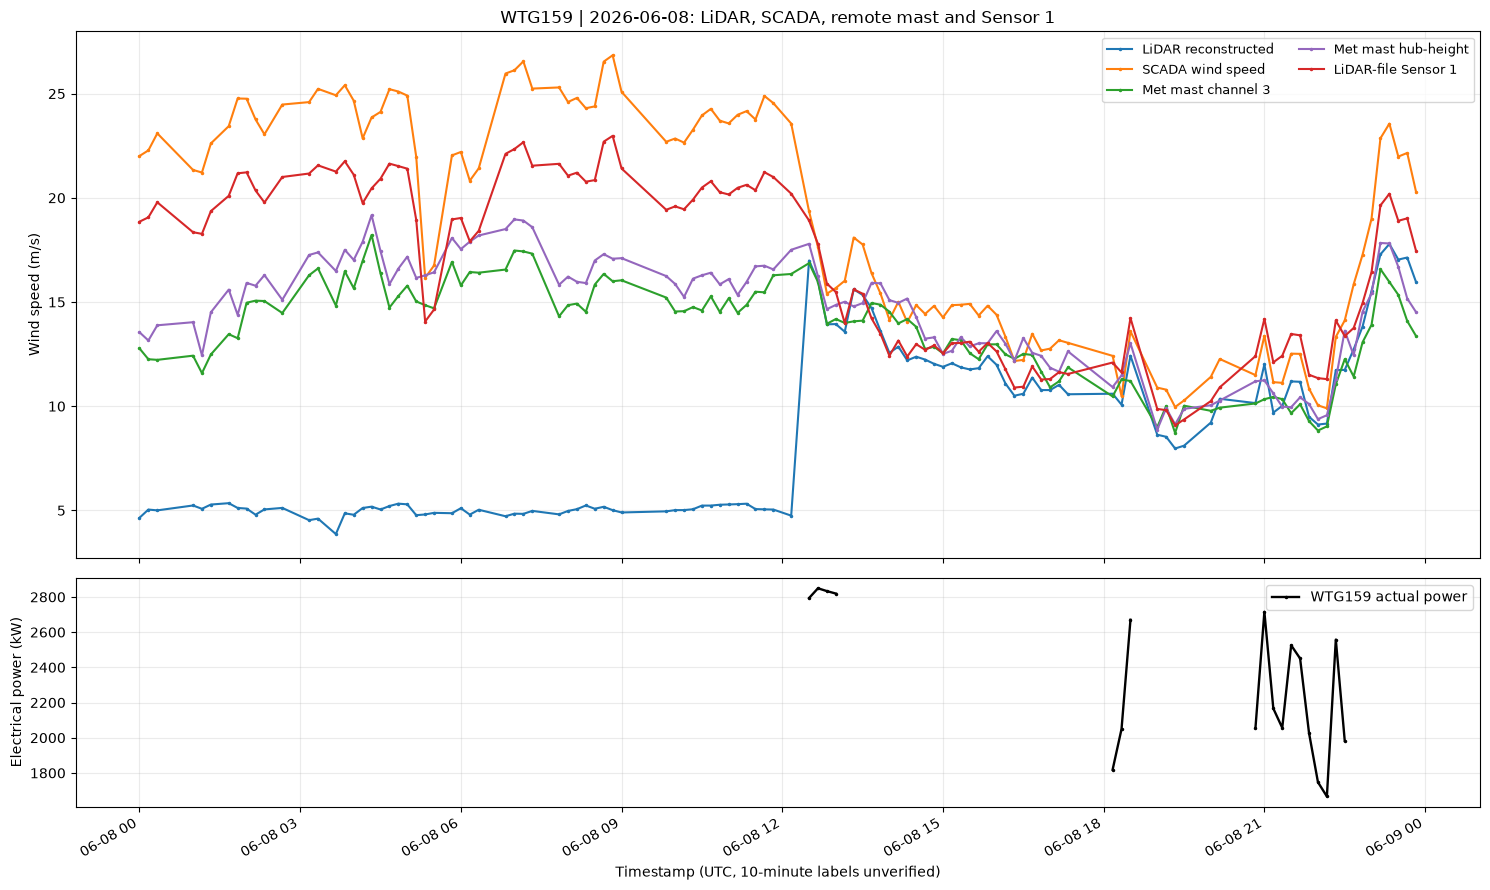

WTG159 June 8 matched 10-minute intervals: 114

Target-turbine signed differences (remote met mast is NOT local ground truth):
turbine                     scenario     n  mean_scada_minus_lidar_ms  median_scada_minus_lidar_ms  mean_scada_minus_mast3_ms  mean_lidar_minus_mast3_ms  mean_scada_over_mast3  mean_lidar_over_mast3  n_distinct_days
 WTG159     All valid triple matches 14590                      1.587                        1.303                      0.384                     -1.204                  1.016                  0.888              134
 WTG159     Exclude 06 anomaly flags 14549                      1.540                        1.301                      0.361                     -1.179                  1.014                  0.890              134
 WTG159 Generation proxy 100–2850 kW 11507                      1.156                        1.190                     -0.108                     -1.264                  0.981                  0.881              126
 WTG159  

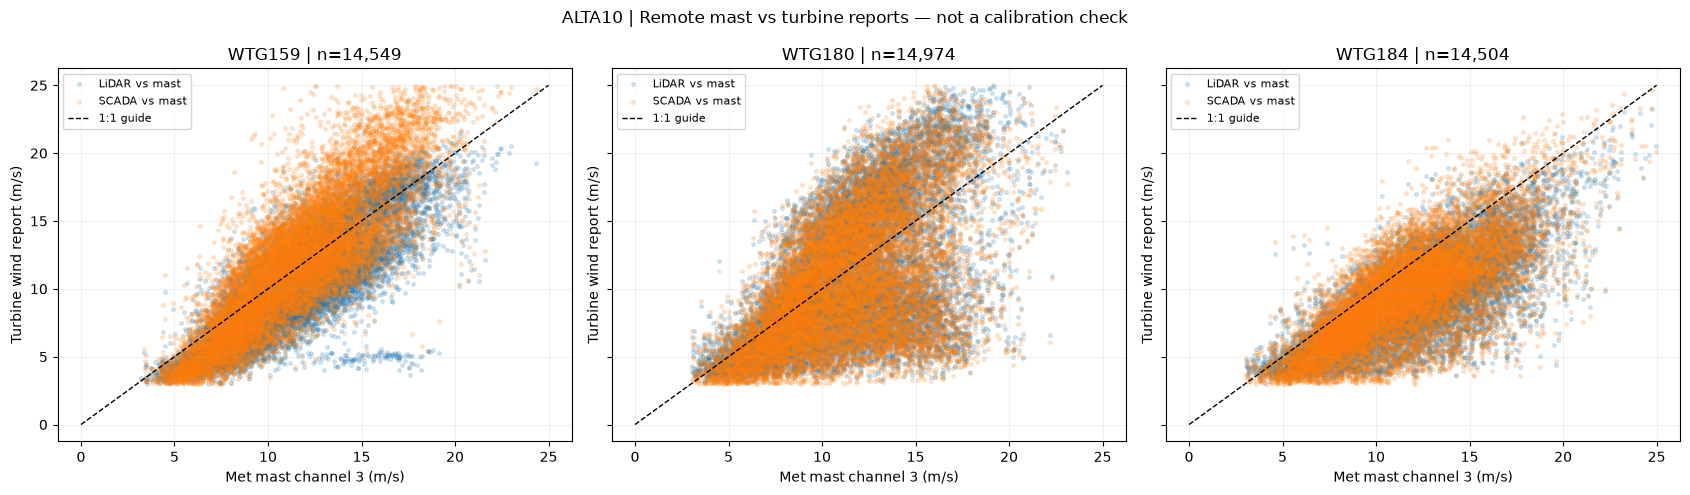

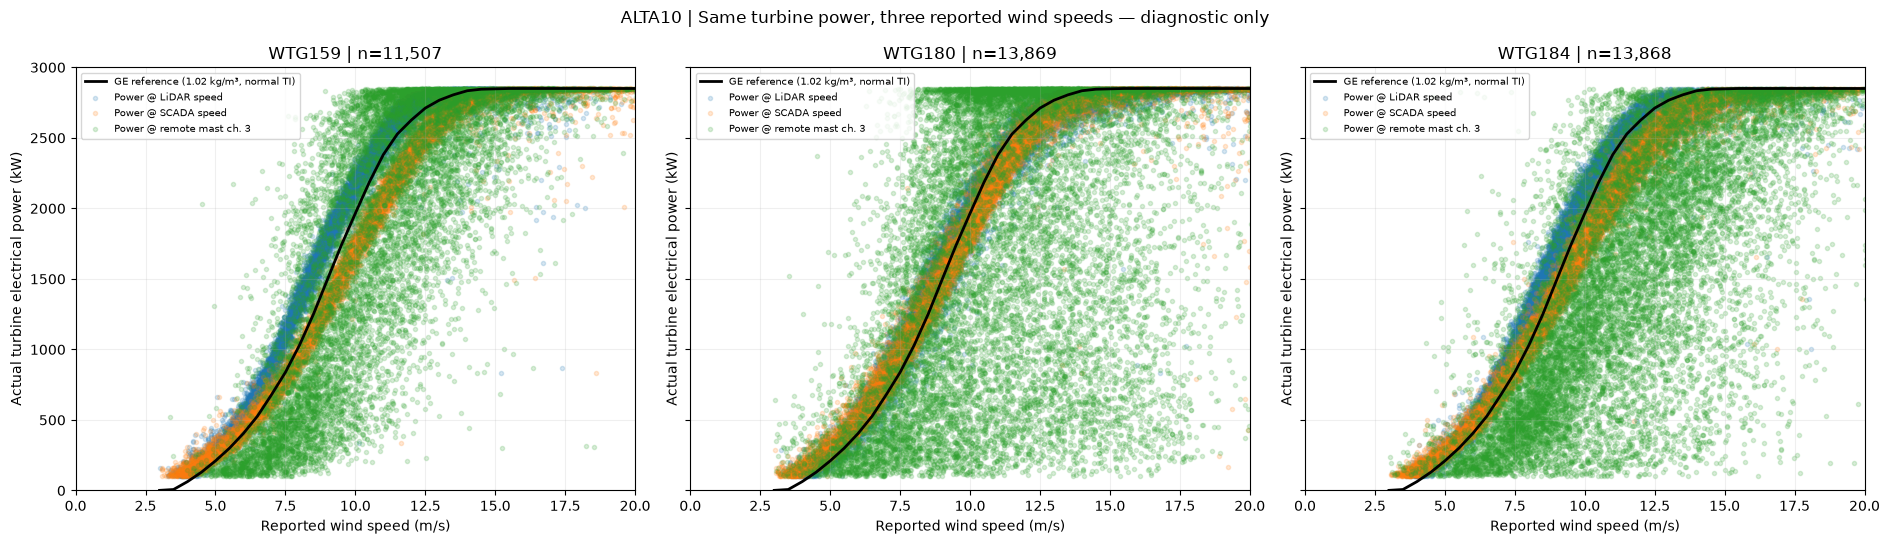


07 COMPLETE. IMPORTANT: no sensor declared faulty or calibrated.
Next: confirm mast coordinates, instrument heights, clock rules, modes and SCADA lineage.


In [19]:
def main():
    global PROJECT_ROOT, DATA_DIR, RESULT_DIR
    PROJECT_ROOT = find_project_root()
    DATA_DIR = PROJECT_ROOT / "data"
    RESULT_DIR = DATA_DIR / "processed" / "07_targeted_sensor_validation"
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    print("Project root:", PROJECT_ROOT)
    print("Output folder:", RESULT_DIR)
    print(f"Candidate Ct at 8.2 m/s = {candidate_ct(8.2):.3f} (provisional 06 curve)")

    scada = load_scada(PROJECT_ROOT)
    mast = load_mast(PROJECT_ROOT)
    pairs = load_lidar_pairs(PROJECT_ROOT, scada)
    require_unique(pairs, ["timestamp", "turbine"], "target matched LiDAR/SCADA")
    print("LiDAR-SCADA rows:", len(pairs), "| Mast rows:", len(mast))
    merged = match_three_sources(pairs, mast)
    print("Triple-source time-matched rows:", len(merged))
    if merged.empty:
        raise ValueError("No aligned 10-minute samples. Confirm source timestamps and interval conventions.")
    for turbine in TARGET_TURBINES:
        print(f"  {turbine}: {sum(merged.turbine.eq(turbine)):,} triple-source samples")

    position = mast_xy()
    # Building the DEM/farm model is needed for low-wake classifications even
    # without mast coordinates, so the mast position is NOT required for this.
    farm, dem_path = load_farm_and_dem(PROJECT_ROOT)
    print("Turbine locations:", len(farm), "| DEM:", dem_path)
    if position is None:
        print("\nMET MAST COORDINATES NOT PROVIDED: skipping mast-position terrain maps.")
        print("Enter MET_MAST_LAT / MET_MAST_LON at top and rerun to generate the map.")
    else:
        plot_mast_terrain_wakes(farm, dem_path, position)

    # This is a new research output; our 06 models and historical charts remain untouched.
    labeled = label_wake_exposure(merged, farm)
    plot_wtg159_event(labeled, PROJECT_ROOT)
    comparisons = screen_target_data(labeled)
    bootstrap_daily_mean(comparisons, "unflagged")
    bootstrap_daily_mean(comparisons, "low_wake_screen")
    plot_target_mast_comparisons(comparisons)
    curve = load_reference_curve(PROJECT_ROOT)
    plot_power_curves(comparisons, curve)
    print("\n07 COMPLETE. IMPORTANT: no sensor declared faulty or calibrated.")
    print("Next: confirm mast coordinates, instrument heights, clock rules, modes and SCADA lineage.")
    return comparisons


if __name__ == "__main__":
    main()
